# Step 12: ablations

This notebook runs the ablation experiments for RQ1, RQ2 and RQ5 on the early sepsis prediction data.

## Setup and input checks

Paths, helpers and the sizes I expect from the earlier steps. The notebook stops here if the inputs do not match.

In [1]:
import os, sys, csv, json, time, gc, hashlib, warnings, contextlib
from pathlib import Path
import numpy as np
import pandas as pd
import pyarrow.parquet as pq
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import skew
from sklearn.base import BaseEstimator, TransformerMixin
from sklearn.ensemble import RandomForestClassifier
from sklearn.exceptions import ConvergenceWarning
from sklearn.linear_model import LogisticRegression
from sklearn.metrics import roc_curve
from sklearn.pipeline import make_pipeline
from tqdm import tqdm

FAST = False
SEED = 42
ABL_TRAIN_ROWS = 250_000
E2_TRAIN_ROWS = 500_000
XH_TRAIN_ROWS = 400_000
FOLDS = [0, 1, 2, 3, 4]
POOL_PATIENT_FRACTION = 1.0
NEG_RATIO = 4
N_TREES = 100
if FAST:
    ABL_TRAIN_ROWS, E2_TRAIN_ROWS, XH_TRAIN_ROWS = 100_000, 200_000, 150_000
    FOLDS = [0, 1, 2]
    N_TREES = 60

COL_SEPTIC, COL_CTRL = "#d1495b", "#2e86ab"
MODELS = ["logistic_regression", "random_forest"]
MCOL = {"logistic_regression": COL_CTRL, "random_forest": COL_SEPTIC}
MLAB = {"logistic_regression": "logistic regression", "random_forest": "random forest"}
METRICS = ["auroc", "auprc", "sens_at_spec90"]

sns.set_theme(style="whitegrid")
pd.set_option("display.float_format", "{:.3f}".format)
pd.set_option("display.width", 220)
pd.set_option("display.max_columns", 40)

SUMMARY, SAVED = [], []
N_PASS = N_FAIL = N_CONV = 0
READY = set()

def log(text=""):
    print(text)
    SUMMARY.append(str(text))

def log_fit(text):
    tqdm.write(text)
    SUMMARY.append(text)

def check(label, ok, detail=""):
    global N_PASS, N_FAIL
    ok = bool(ok)
    N_PASS += ok
    N_FAIL += (not ok)
    log(f"[{'PASS' if ok else 'FAIL'}] {label}" + (f" ({detail})" if detail != "" else ""))
    return ok

def expect(label, observed, expected, tol=0):
    return check(label, abs(observed - expected) <= tol, f"observed {observed}, expected {expected}")

@contextlib.contextmanager
def guarded(label):
    try:
        yield
    except Exception as e:
        check(label, False, f"{type(e).__name__}: {e}")

@contextlib.contextmanager
def timed(label):
    t0 = time.time()
    try:
        yield
    finally:
        log(f"{label}: {time.time() - t0:.1f} s")

def save_fig(name):
    plt.tight_layout()
    p = FIG / name
    plt.savefig(p, dpi=150)
    SAVED.append(str(p))
    plt.show()
    plt.close()

def need(*names):
    miss = [n for n in names if n not in READY]
    if miss:
        raise RuntimeError("stopping: an earlier section did not finish, missing " + ", ".join(miss))

def find_root():
    here = Path.cwd().resolve()
    for p in [here, *here.parents]:
        if (p / "dataset").is_dir():
            return p
    raise RuntimeError(f"no folder with a dataset directory above {here}")

ROOT = find_root()
PROC, TAB, FIG, SRC = ROOT / "data" / "processed", ROOT / "results" / "tables", ROOT / "results" / "figures", ROOT / "src"
for p in (TAB, FIG):
    p.mkdir(parents=True, exist_ok=True)
sys.path.insert(0, str(SRC))
import sepsis_eval as ev

P_FLAT, P_RATE = PROC / "features_flat.parquet", PROC / "rate_features.parquet"
P_SETS, P_SPLIT = PROC / "feature_sets_v2.json", PROC / "patient_splits.csv"

def append_rows(path, cols, rows):
    new = not path.exists()
    with open(path, "a", newline="") as f:
        w = csv.writer(f)
        if new:
            w.writerow(cols)
        for r in rows:
            w.writerow([r[c] for c in cols])
        f.flush()
        os.fsync(f.fileno())

def done_keys(path, cols):
    if not path.exists():
        return set()
    d = pd.read_csv(path, usecols=cols, dtype=str)
    return set(map(tuple, d[cols].values.tolist()))

def sens90(y, s):
    fpr, tpr, _ = roc_curve(y, s)
    return float(tpr[fpr <= 0.10].max())

def metrics3(y, s):
    cm = ev.curve_metrics(y, s)
    return {"auroc": cm["auroc"], "auprc": cm["auprc"], "sens_at_spec90": sens90(y, s)}

def summarize(df, keys):
    g = df.groupby(keys, sort=False)[METRICS].agg(["mean", "std"])
    g.columns = [f"{a}_{b}" for a, b in g.columns]
    return g.reset_index()

log(f"root: {ROOT}")
log(f"FAST={FAST}, folds={FOLDS}, E1 rows={ABL_TRAIN_ROWS}, E2 rows={E2_TRAIN_ROWS}, E3 rows={XH_TRAIN_ROWS}, trees={N_TREES}")

root: /Users/harnoorkaur/Downloads/Sepsis_ml
FAST=False, folds=[0, 1, 2, 3, 4], E1 rows=250000, E2 rows=500000, E3 rows=400000, trees=100


In [2]:
EXPECTED_SIZES = {"raw_values": 41, "raw_values_with_missingness": 109, "no_missingness": 134, "all": 239,
                  "with_rates": 239, "no_counts_no_rates": 204, "no_icu_time": 237, "vitals_only": 123,
                  "core": 50, "cnt_cols": 35, "rate_cols": 35, "masks_only": 34}

with timed("section 1"):
    SPL = pd.read_csv(P_SPLIT, dtype={"patient_id": str, "hospital": str})
    META = pd.read_parquet(P_FLAT, columns=["patient_id", "hospital", "hour", "split", "SepsisLabel"])
    PID_ALL = META.patient_id.astype(str).to_numpy()
    HOSP_ALL = META.hospital.astype(str).to_numpy()
    Y_ALL = META.SepsisLabel.to_numpy().astype(np.int8)
    SETS = json.load(open(P_SETS))

    def pool_structure_checks(tag):
        in_pool = SPL.split.astype(str).isin(["train", "val"])
        pool = SPL[SPL.cv_fold >= 0]
        pool_rows = META.split.astype(str).isin(["train", "val"]).to_numpy()
        expect(f"{tag}: pool patients", len(pool), 34285)
        expect(f"{tag}: pool rows", int(pool_rows.sum()), 1_319_995)
        ok = sorted(pool.cv_fold.unique().tolist()) == [0, 1, 2, 3, 4] and bool(((SPL.cv_fold >= 0) == in_pool).all()) and bool((SPL.loc[~in_pool, "cv_fold"] == -1).all())
        check(f"{tag}: cv_fold is 0 to 4 exactly on the pool patients", ok)
        parts = [set(pool.patient_id[pool.cv_fold == f]) for f in range(5)]
        union = set().union(*parts)
        ok = sum(map(len, parts)) == len(union) == len(pool) and union == set(PID_ALL[pool_rows])
        check(f"{tag}: held-out parts of the five folds partition the pool patients", ok, ", ".join(str(len(p)) for p in parts))

    n_fail0 = N_FAIL
    expect("rows in features_flat", len(META), 1_552_210)
    pool_structure_checks("input")
    rm = pd.read_parquet(P_RATE, columns=["patient_id", "hour"])
    aligned = len(rm) == len(META) and np.array_equal(rm.patient_id.astype(str).to_numpy(), PID_ALL) and np.array_equal(rm.hour.to_numpy(), META.hour.to_numpy())
    check("rate_features is row-aligned with features_flat", aligned, f"{len(rm)} rows")
    del rm
    for s, n in EXPECTED_SIZES.items():
        expect(f"size of {s}", len(SETS[s]), n)
    if N_FAIL > n_fail0:
        raise RuntimeError("stopping: the inputs do not match the project description, see the failed checks above")
    READY.add("inputs")

    pool_rate = Y_ALL[np.isin(META.split.astype(str).to_numpy(), ["train", "val"])].mean()
    expect("pool positive row rate", round(float(pool_rate), 4), 0.018, 0.002)
    for h, r in [("A", 0.0217), ("B", 0.0141)]:
        expect(f"row-level positive rate, hospital {h}", round(float(Y_ALL[HOSP_ALL == h].mean()), 4), r, 0.0005)
    for h, n, r in [("A", 20336, 0.0880), ("B", 20000, 0.0571)]:
        d = SPL[SPL.hospital == h]
        expect(f"patients in hospital {h}", len(d), n)
        expect(f"septic patient rate, hospital {h}", round(float(d.ever_septic.astype(float).mean()), 4), r, 0.0005)

[PASS] rows in features_flat (observed 1552210, expected 1552210)
[PASS] input: pool patients (observed 34285, expected 34285)
[PASS] input: pool rows (observed 1319995, expected 1319995)
[PASS] input: cv_fold is 0 to 4 exactly on the pool patients
[PASS] input: held-out parts of the five folds partition the pool patients (6857, 6857, 6857, 6857, 6857)
[PASS] rate_features is row-aligned with features_flat (1552210 rows)
[PASS] size of raw_values (observed 41, expected 41)
[PASS] size of raw_values_with_missingness (observed 109, expected 109)
[PASS] size of no_missingness (observed 134, expected 134)
[PASS] size of all (observed 239, expected 239)
[PASS] size of with_rates (observed 239, expected 239)
[PASS] size of no_counts_no_rates (observed 204, expected 204)
[PASS] size of no_icu_time (observed 237, expected 237)
[PASS] size of vitals_only (observed 123, expected 123)
[PASS] size of core (observed 50, expected 50)
[PASS] size of cnt_cols (observed 35, expected 35)
[PASS] size of 

## Feature sets

Five new sets are built from the v2 sets and saved together as v3. Every member is checked against the parquet columns.

In [3]:
DEFS = {
    "raw_values": "current values of the variables plus the static columns",
    "raw_values_with_missingness": "raw_values plus the masks and the time since last measurement",
    "no_missingness": "all features without masks, time since last measurement and counts",
    "all": "every causal feature",
    "no_icu_time": "all without ICULOS and HospAdmTime",
    "vitals_only": "features of the vitals only, from the v2 file",
    "cnt_cols": "the 34 cumulative count columns plus n_labs_so_far",
    "rate_cols": "the 34 measurement rates plus rate_labs, read from rate_features",
    "with_rates": "all without the count columns, plus the rate columns",
    "no_counts_no_rates": "all without the count columns",
    "core": "small core set from the v2 file",
    "masks_only": "the 34 measurement masks",
    "counts_only": "cnt_cols",
    "rates_only": "rate_cols",
    "time_only": "ICULOS and HospAdmTime",
    "core_no_counts": "core without the members of cnt_cols",
    "all_no_hospital_habits": "all without unit_1, unit_2, unit_unknown, ICULOS and HospAdmTime",
}
E1_SETS = ["raw_values", "raw_values_with_missingness", "no_missingness", "all", "with_rates", "no_counts_no_rates",
           "no_icu_time", "vitals_only", "core", "core_no_counts", "counts_only", "rates_only", "time_only"]

with timed("section 2"):
    need("inputs")
    SETS.update({
        "counts_only": list(SETS["cnt_cols"]),
        "rates_only": list(SETS["rate_cols"]),
        "time_only": ["ICULOS", "HospAdmTime"],
        "core_no_counts": [c for c in SETS["core"] if c not in set(SETS["cnt_cols"])],
        "all_no_hospital_habits": [c for c in SETS["all"] if c not in {"unit_1", "unit_2", "unit_unknown", "ICULOS", "HospAdmTime"}],
    })
    FLAT_COLS = set(pq.ParquetFile(P_FLAT).schema_arrow.names)
    RATE_NAMES = set(pq.ParquetFile(P_RATE).schema_arrow.names)
    where_ok = lambda c: (c in RATE_NAMES) if c.startswith("rate_") else (c in FLAT_COLS)
    for s, cols in SETS.items():
        miss = [c for c in cols if not where_ok(c)]
        check(f"members of {s} exist in the parquet files", not miss and len(cols) == len(set(cols)), f"{len(cols)} features" + (f", missing {miss[:3]}" if miss else ""))
    json.dump({k: list(v) for k, v in SETS.items()}, open(PROC / "feature_sets_v3.json", "w"))
    defs = pd.DataFrame({"set": list(SETS), "n_features": [len(v) for v in SETS.values()],
                         "how it is defined": [DEFS.get(k, "from feature_sets_v2") for k in SETS]})
    defs.to_csv(TAB / "ablation_feature_set_definitions.csv", index=False)
    print(defs.to_string(index=False))
    READY.add("sets")

[PASS] members of all exist in the parquet files (239 features)
[PASS] members of no_missingness exist in the parquet files (134 features)
[PASS] members of no_icu_time exist in the parquet files (237 features)
[PASS] members of vitals_only exist in the parquet files (123 features)
[PASS] members of raw_values exist in the parquet files (41 features)
[PASS] members of raw_values_with_missingness exist in the parquet files (109 features)
[PASS] members of cnt_cols exist in the parquet files (35 features)
[PASS] members of rate_cols exist in the parquet files (35 features)
[PASS] members of all_plus_rates exist in the parquet files (274 features)
[PASS] members of with_counts exist in the parquet files (239 features)
[PASS] members of with_rates exist in the parquet files (239 features)
[PASS] members of no_counts_no_rates exist in the parquet files (204 features)
[PASS] members of core exist in the parquet files (50 features)
[PASS] members of core_no_icu_time exist in the parquet files

## Pool and loader

The train and val patients are read once into one float32 array and the sets are indexed by column position. fit_eval fits a fresh model on given rows and scores the held-out rows.

In [4]:
class Prep(BaseEstimator, TransformerMixin):
    def _fill(self, X):
        X = np.asarray(X, dtype=np.float32)
        return np.where(np.isnan(X), self.med_, X)

    def _log(self, X):
        c = self.log_
        if c.any():
            X[:, c] = np.sign(X[:, c]) * np.log1p(np.abs(X[:, c]))
        return X

    def fit(self, X, y=None):
        X = np.asarray(X, dtype=np.float32)
        med = np.nanmedian(X, axis=0)
        self.med_ = np.where(np.isnan(med), 0, med).astype(np.float32)
        Xf = self._fill(X)
        self.bin_ = ((Xf == 0) | (Xf == 1)).all(axis=0)
        sk = np.concatenate([skew(Xf[:, i:i + 50].astype(np.float64), axis=0) for i in range(0, Xf.shape[1], 50)])
        self.log_ = (np.abs(np.nan_to_num(sk)) > 3) & ~self.bin_
        Xf = self._log(Xf)
        sd = Xf.std(axis=0)
        self.mu_ = np.where(self.bin_, 0, Xf.mean(axis=0)).astype(np.float32)
        self.sd_ = np.where(self.bin_ | (sd == 0), 1, sd).astype(np.float32)
        return self

    def transform(self, X):
        return (self._log(self._fill(X)) - self.mu_) / self.sd_

def build_model(name, class_mode):
    bal = class_mode == "balanced"
    if name == "logistic_regression":
        return make_pipeline(Prep(), LogisticRegression(C=0.001, class_weight="balanced" if bal else None, max_iter=300, solver="lbfgs"))
    return RandomForestClassifier(n_estimators=N_TREES, max_depth=12, min_samples_leaf=300, max_features="sqrt",
                                  class_weight="balanced_subsample" if bal else None, n_jobs=-1, random_state=SEED)

def fit_quiet(model, X, y):
    global N_CONV
    with warnings.catch_warnings(record=True) as w:
        warnings.simplefilter("always")
        model.fit(X, y)
    N_CONV += sum(issubclass(x.category, ConvergenceWarning) for x in w)

def predict_chunked(model, Xm, cols, rows, bs=100_000):
    out = [model.predict_proba(Xm[np.ix_(rows[i:i + bs], cols)])[:, 1] for i in range(0, len(rows), bs)]
    return np.concatenate(out)

def fit_scores(Xm, ym, cols, model_name, tr, tests, class_mode):
    Xtr = Xm[np.ix_(tr, cols)]
    model = build_model(model_name, class_mode)
    t0 = time.time()
    fit_quiet(model, Xtr, ym[tr])
    sec = time.time() - t0
    del Xtr
    return [predict_chunked(model, Xm, cols, te) for te in tests], sec

def load_block(row_pos, cols, chunk=40, desc="reading columns"):
    out = np.empty((len(row_pos), len(cols)), dtype=np.float32)
    for path, pick in [(P_FLAT, [j for j, c in enumerate(cols) if not c.startswith("rate_")]),
                       (P_RATE, [j for j, c in enumerate(cols) if c.startswith("rate_")])]:
        for i in tqdm(range(0, len(pick), chunk), desc=f"{desc} {path.stem}", leave=False):
            js = pick[i:i + chunk]
            df = pd.read_parquet(path, columns=[cols[j] for j in js])
            out[:, js] = df.to_numpy(dtype=np.float32)[row_pos]
            del df
    return out

def peak_mb():
    try:
        import resource
        r = resource.getrusage(resource.RUSAGE_SELF).ru_maxrss
        return r / 1e6 if sys.platform == "darwin" else r / 1e3
    except Exception:
        return float("nan")

with timed("section 3"):
    need("sets")
    SPL_IDX = SPL.set_index("patient_id")
    pool_pids = SPL.loc[SPL.cv_fold >= 0, "patient_id"].to_numpy()
    if POOL_PATIENT_FRACTION < 1:
        pool_pids = np.random.default_rng(SEED).choice(pool_pids, size=int(round(len(pool_pids) * POOL_PATIENT_FRACTION)), replace=False)
    ROWPOS = np.flatnonzero(META.patient_id.isin(pool_pids).to_numpy())
    Y = Y_ALL[ROWPOS]
    FOLD_ROW = META.patient_id.iloc[ROWPOS].map(SPL_IDX["cv_fold"]).to_numpy().astype(np.int8)
    PCODE = pd.factorize(META.patient_id.iloc[ROWPOS])[0]
    COLS = list(dict.fromkeys(c for s in E1_SETS for c in SETS[s]))
    COLPOS = {c: i for i, c in enumerate(COLS)}
    SETIDX = {s: np.array([COLPOS[c] for c in SETS[s]]) for s in E1_SETS}
    X = load_block(ROWPOS, COLS, desc="pool")
    log(f"pool: {len(pool_pids)} patients, {len(ROWPOS)} rows, {X.shape[1]} columns, {Y.mean() * 100:.2f}% positive rows")
    log(f"pool array {X.nbytes / 1e9:.2f} GB, peak process memory {peak_mb():.0f} MB")

    def train_rows(fold, n):
        cand = np.flatnonzero(FOLD_ROW != fold)
        if n >= len(cand):
            return cand
        return np.sort(np.random.default_rng(SEED + fold).choice(cand, size=n, replace=False))

    def heldout_rows(fold):
        return np.flatnonzero(FOLD_ROW == fold)

    def row_hash(idx):
        return hashlib.md5(np.ascontiguousarray(idx, dtype=np.int64).tobytes()).hexdigest()

    def fit_eval(set_name, model_name, train_idx, test_idx, class_mode):
        (s,), sec = fit_scores(X, Y, SETIDX[set_name], model_name, train_idx, [test_idx], class_mode)
        r = metrics3(Y[test_idx], s)
        r["fit_seconds"] = round(sec, 1)
        return r

    READY.add("pool")

pool: 34285 patients, 1319995 rows, 274 columns, 1.80% positive rows
pool array 1.45 GB, peak process memory 3361 MB
section 3: 6.9 s


## E1, feature-set ablation

Every feature set is fitted with both models on the same training rows in each fold, and scored on all held-out rows. Each fit is appended to a csv, so a rerun continues where it stopped.

In [5]:
P_E1 = TAB / "ablation_feature_sets_folds.csv"
KEY1 = ["experiment", "set", "model", "fold"]
E1_COLS = ["experiment", "set", "n_features", "model", "fold", "train_rows", "heldout_rows", "auroc", "auprc", "sens_at_spec90", "fit_seconds"]
HASH1 = {}

with timed("section 4"):
    need("pool", "sets")
    done = done_keys(P_E1, KEY1)
    log(f"E1: {len(E1_SETS)} sets x {len(MODELS)} models x {len(FOLDS)} folds, {len(done)} fits already in the csv")
    bar = tqdm(E1_SETS, desc="E1 sets")
    for s in bar:
        bar.set_description(f"E1 {s}")
        for m in MODELS:
            for f in FOLDS:
                tr, te = train_rows(f, ABL_TRAIN_ROWS), heldout_rows(f)
                HASH1[(s, m, f)] = row_hash(tr)
                if ("E1", s, m, str(f)) in done:
                    continue
                r = fit_eval(s, m, tr, te, "balanced")
                row = {"experiment": "E1", "set": s, "n_features": len(SETS[s]), "model": m, "fold": f,
                       "train_rows": len(tr), "heldout_rows": len(te), **r}
                append_rows(P_E1, E1_COLS, [row])
                log_fit(f"{s:28s} {m:20s} fold {f}  auroc {r['auroc']:.3f}  auprc {r['auprc']:.3f}  sens@90 {r['sens_at_spec90']:.3f}  {r['fit_seconds']:.0f}s")

    E1 = pd.read_csv(P_E1)
    E1 = E1[E1["set"].isin(E1_SETS)]
    SUM1 = summarize(E1, ["set", "n_features", "model"])
    SUM1["set"] = pd.Categorical(SUM1["set"], E1_SETS, ordered=True)
    SUM1 = SUM1.sort_values(["model", "set"]).reset_index(drop=True)
    SUM1["set"] = SUM1["set"].astype(str)
    REF = None
    P_M4 = TAB / "m4_cv_summary.csv"
    if P_M4.exists():
        m4 = pd.read_csv(P_M4)
        r = m4[m4["model"] == "M4b_bnb_masks"]
        if len(r):
            r = r.iloc[0]
            REF = {"set": "masks_only", "n_features": 34, "model": "bernoulli_nb_reference",
                   "auroc_mean": r.auroc_mean, "auroc_std": r.auroc_std, "auprc_mean": r.auprc_mean, "auprc_std": r.auprc_std,
                   "sens_at_spec90_mean": np.nan, "sens_at_spec90_std": np.nan}
    out = pd.concat([SUM1, pd.DataFrame([REF])], ignore_index=True) if REF else SUM1
    out.to_csv(TAB / "ablation_feature_sets_summary.csv", index=False)
    print(out.to_string(index=False))
    log(f"E1 csv: {len(E1)} fits, {N_CONV} convergence warnings counted so far")
    READY.add("e1")

E1: 13 sets x 2 models x 5 folds, 130 fits already in the csv


E1 time_only: 100%|██████████| 13/13 [00:02<00:00,  4.42it/s]                 

                        set  n_features                  model  auroc_mean  auroc_std  auprc_mean  auprc_std  sens_at_spec90_mean  sens_at_spec90_std
                 raw_values          41    logistic_regression       0.730      0.010       0.061      0.006                0.383               0.013
raw_values_with_missingness         109    logistic_regression       0.787      0.010       0.088      0.006                0.464               0.015
             no_missingness         134    logistic_regression       0.773      0.010       0.077      0.012                0.434               0.022
                        all         239    logistic_regression       0.809      0.009       0.095      0.011                0.491               0.018
                 with_rates         239    logistic_regression       0.811      0.009       0.095      0.011                0.493               0.018
         no_counts_no_rates         204    logistic_regression       0.804      0.008       0.095   

## Paired differences

For each comparison I take the per-fold difference between two feature sets, for both models. The plots show the mean AUPRC difference with the spread over folds.

missingness_raw [logistic regression]: raw_values_with_missingness minus raw_values: mean AUROC diff +0.0566, mean AUPRC diff +0.0270, A better in 5 of 5 folds (AUROC) and 5 of 5 folds (AUPRC)
missingness_raw [random forest]: raw_values_with_missingness minus raw_values: mean AUROC diff +0.0074, mean AUPRC diff +0.0053, A better in 5 of 5 folds (AUROC) and 5 of 5 folds (AUPRC)
missingness_all [logistic regression]: all minus no_missingness: mean AUROC diff +0.0364, mean AUPRC diff +0.0188, A better in 5 of 5 folds (AUROC) and 5 of 5 folds (AUPRC)
missingness_all [random forest]: all minus no_missingness: mean AUROC diff +0.0122, mean AUPRC diff +0.0038, A better in 5 of 5 folds (AUROC) and 5 of 5 folds (AUPRC)
rates_vs_counts_isolated [logistic regression]: rates_only minus counts_only: mean AUROC diff -0.0536, mean AUPRC diff -0.0289, A better in 0 of 5 folds (AUROC) and 0 of 5 folds (AUPRC)
rates_vs_counts_isolated [random forest]: rates_only minus counts_only: mean AUROC diff -0.030

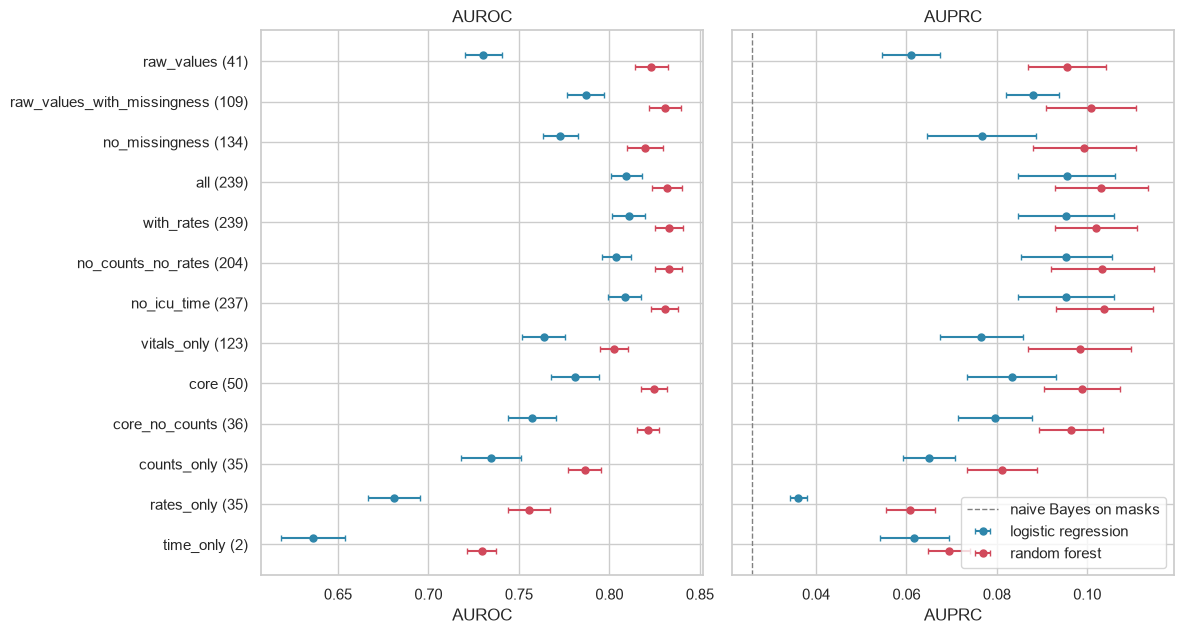

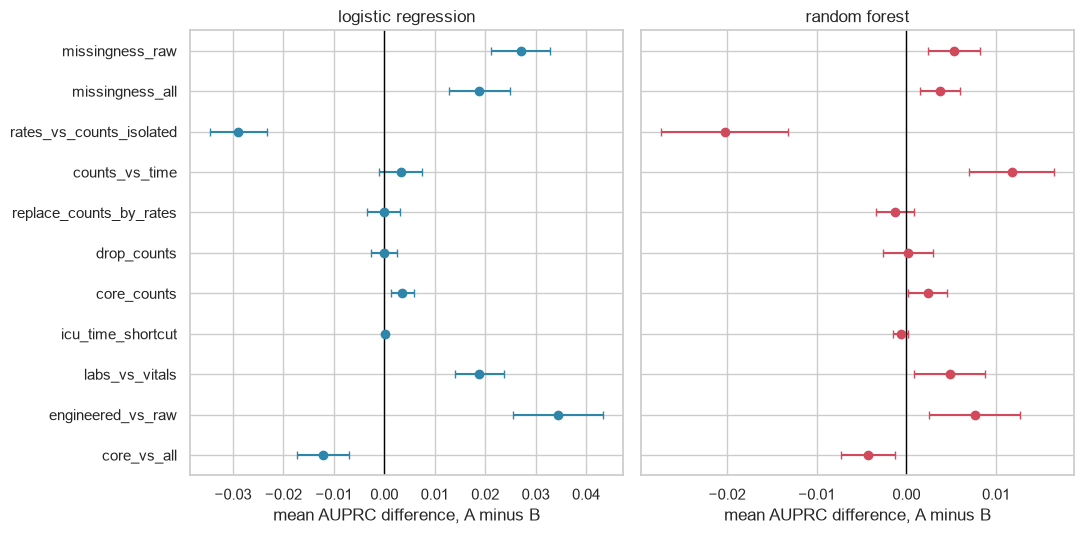

section 5: 0.8 s


In [6]:
COMPS = [
    ("missingness_raw", "do the missingness columns help on top of the raw values", "raw_values_with_missingness", "raw_values"),
    ("missingness_all", "do the missingness columns help on top of the engineered features", "all", "no_missingness"),
    ("rates_vs_counts_isolated", "do rates beat cumulative counts when used alone", "rates_only", "counts_only"),
    ("counts_vs_time", "do counts beat the stay-time columns alone", "counts_only", "time_only"),
    ("replace_counts_by_rates", "what changes when counts are replaced by rates", "with_rates", "all"),
    ("drop_counts", "what changes when the counts are dropped", "no_counts_no_rates", "all"),
    ("core_counts", "do counts matter inside the core set", "core", "core_no_counts"),
    ("icu_time_shortcut", "how much do ICULOS and HospAdmTime add", "all", "no_icu_time"),
    ("labs_vs_vitals", "what do the labs add over the vitals", "all", "vitals_only"),
    ("engineered_vs_raw", "do engineered features help over the raw values", "all", "raw_values"),
    ("core_vs_all", "does the small core set match the full set", "core", "all"),
]

def paired(df, comps):
    rows = []
    for name, q, a, b in comps:
        for m in MODELS:
            d = df[df["model"] == m]
            for met in METRICS:
                pa = d[d["set"] == a].set_index("fold")[met]
                pb = d[d["set"] == b].set_index("fold")[met]
                diff = (pa - pb).dropna()
                rows.append({"comparison": name, "question": q, "set_a": a, "set_b": b, "model": m, "metric": met,
                             "mean_diff": diff.mean(), "std_diff": diff.std(), "folds_a_better": int((diff > 0).sum()), "n_folds": len(diff)})
    return pd.DataFrame(rows)

with timed("section 5"):
    need("e1")
    PD = paired(E1, COMPS)
    PD.drop(columns="n_folds").to_csv(TAB / "ablation_paired_differences.csv", index=False)
    for name, q, a, b in COMPS:
        for m in MODELS:
            d = PD[(PD.comparison == name) & (PD.model == m)].set_index("metric")
            log(f"{name} [{MLAB[m]}]: {a} minus {b}: mean AUROC diff {d.loc['auroc', 'mean_diff']:+.4f}, mean AUPRC diff {d.loc['auprc', 'mean_diff']:+.4f}, "
                f"A better in {d.loc['auroc', 'folds_a_better']} of {d.loc['auroc', 'n_folds']} folds (AUROC) and {d.loc['auprc', 'folds_a_better']} of {d.loc['auprc', 'n_folds']} folds (AUPRC)")

    fig, axes = plt.subplots(1, 2, figsize=(12, 6.5), sharey=True)
    ypos = np.arange(len(E1_SETS))
    for ax, met in zip(axes, ["auroc", "auprc"]):
        for m, off in zip(MODELS, [-0.15, 0.15]):
            d = SUM1[SUM1.model == m].set_index("set").loc[E1_SETS]
            ax.errorbar(d[f"{met}_mean"], ypos + off, xerr=d[f"{met}_std"].fillna(0), fmt="o", ms=5, capsize=2, color=MCOL[m], label=MLAB[m])
        if REF is not None and met == "auprc":
            ax.axvline(REF["auprc_mean"], color="gray", ls="--", lw=1, label="naive Bayes on masks")
        ax.set_title(met.upper())
        ax.set_xlabel(met.upper())
    nf = SUM1[SUM1.model == MODELS[0]].set_index("set").loc[E1_SETS, "n_features"]
    axes[0].set_yticks(ypos)
    axes[0].set_yticklabels([f"{s} ({nf[s]})" for s in E1_SETS])
    axes[0].invert_yaxis()
    axes[1].legend(loc="lower right")
    save_fig("fig12_feature_set_ablation.png")

    fig, axes = plt.subplots(1, 2, figsize=(11, 5.5), sharey=True)
    names = [c[0] for c in COMPS]
    for ax, m in zip(axes, MODELS):
        d = PD[(PD.model == m) & (PD.metric == "auprc")].set_index("comparison").loc[names]
        ax.errorbar(d.mean_diff, np.arange(len(names)), xerr=d.std_diff.fillna(0), fmt="o", capsize=3, color=MCOL[m])
        ax.axvline(0, color="black", lw=1)
        ax.set_title(MLAB[m])
        ax.set_xlabel("mean AUPRC difference, A minus B")
    axes[0].set_yticks(np.arange(len(names)))
    axes[0].set_yticklabels(names)
    axes[0].invert_yaxis()
    save_fig("fig12_paired_differences.png")

## E2, imbalance handling

The core set is fitted with no weights, with class weights and with the negatives downsampled. Only the training rows or the weights change between settings.

E2: 3 settings x 2 models x 5 folds, 9 fits already in the csv


E2 class_weight:  33%|███▎      | 1/3 [00:41<01:22, 41.30s/it]

none          random_forest        fold 4  auroc 0.824  auprc 0.094  sens@90 0.497  40s


E2 class_weight:  33%|███▎      | 1/3 [00:44<01:22, 41.30s/it]

class_weight  logistic_regression  fold 0  auroc 0.771  auprc 0.073  sens@90 0.434  2s


E2 class_weight:  33%|███▎      | 1/3 [00:47<01:22, 41.30s/it]

... (33 outputs left out)

E2 downsample:  67%|██████▋   | 2/3 [04:58<02:34, 154.85s/it]

downsample    random_forest        fold 3  auroc 0.816  auprc 0.101  sens@90 0.512  4s


E2 downsample: 100%|██████████| 3/3 [05:03<00:00, 101.25s/it]


downsample    random_forest        fold 4  auroc 0.819  auprc 0.091  sens@90 0.487  4s
     setting               model  auroc_mean  auroc_std  auprc_mean  auprc_std  sens_at_spec90_mean  sens_at_spec90_std
        none logistic_regression       0.773      0.012       0.088      0.009                0.466               0.019
        none       random_forest       0.825      0.007       0.105      0.011                0.518               0.020
class_weight logistic_regression       0.782      0.013       0.084      0.009                0.461               0.022
class_weight       random_forest       0.828      0.007       0.101      0.009                0.517               0.016
  downsample logistic_regression       0.779      0.014       0.086      0.009                0.463               0.018
  downsample       random_forest       0.822      0.007       0.099      0.009                0.510               0.019


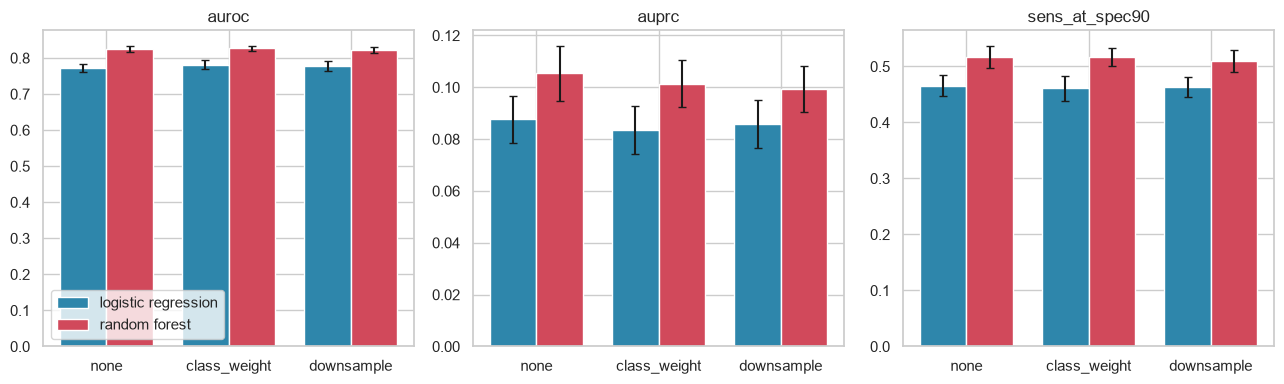

note: AUROC, AUPRC and sensitivity at 90% specificity only use the order of the scores, so class weighting moves them little; what changes is where the thresholds sit.
section 6: 304.1 s


In [7]:
P_E2 = TAB / "ablation_imbalance_folds.csv"
KEY2 = ["setting", "model", "fold"]
E2_COLS = ["setting", "model", "fold", "train_rows", "positives_in_train", "auroc", "auprc", "sens_at_spec90", "fit_seconds"]
E2_SETTINGS = ["none", "class_weight", "downsample"]
E2_MODE = {"none": "none", "class_weight": "balanced", "downsample": "none"}
HASH2 = {}

def e2_rows(setting, f):
    if setting != "downsample":
        return train_rows(f, E2_TRAIN_ROWS)
    cand = np.flatnonzero(FOLD_ROW != f)
    pos, neg = cand[Y[cand] == 1], cand[Y[cand] == 0]
    keep = np.random.default_rng(SEED + f).choice(neg, size=min(len(neg), NEG_RATIO * len(pos)), replace=False)
    return np.sort(np.concatenate([pos, keep]))

with timed("section 6"):
    need("pool", "sets")
    done = done_keys(P_E2, KEY2)
    log(f"E2: {len(E2_SETTINGS)} settings x {len(MODELS)} models x {len(FOLDS)} folds, {len(done)} fits already in the csv")
    bar = tqdm(E2_SETTINGS, desc="E2 settings")
    for st in bar:
        bar.set_description(f"E2 {st}")
        for m in MODELS:
            for f in FOLDS:
                tr, te = e2_rows(st, f), heldout_rows(f)
                HASH2[(st, m, f)] = row_hash(tr)
                if (st, m, str(f)) in done:
                    continue
                r = fit_eval("core", m, tr, te, E2_MODE[st])
                row = {"setting": st, "model": m, "fold": f, "train_rows": len(tr), "positives_in_train": int(Y[tr].sum()), **r}
                append_rows(P_E2, E2_COLS, [row])
                log_fit(f"{st:13s} {m:20s} fold {f}  auroc {r['auroc']:.3f}  auprc {r['auprc']:.3f}  sens@90 {r['sens_at_spec90']:.3f}  {r['fit_seconds']:.0f}s")

    E2 = pd.read_csv(P_E2)
    SUM2 = summarize(E2, ["setting", "model"])
    SUM2.to_csv(TAB / "ablation_imbalance_summary.csv", index=False)
    print(SUM2.to_string(index=False))

    fig, axes = plt.subplots(1, 3, figsize=(13, 4))
    x, w = np.arange(len(E2_SETTINGS)), 0.38
    for ax, met in zip(axes, METRICS):
        for k, m in enumerate(MODELS):
            d = SUM2[SUM2.model == m].set_index("setting").loc[E2_SETTINGS]
            ax.bar(x + (k - 0.5) * w, d[f"{met}_mean"], w, yerr=d[f"{met}_std"].fillna(0), capsize=3, color=MCOL[m], label=MLAB[m])
        ax.set_xticks(x)
        ax.set_xticklabels(E2_SETTINGS)
        ax.set_title(met)
    axes[0].legend()
    save_fig("fig12_imbalance.png")
    log("note: AUROC, AUPRC and sensitivity at 90% specificity only use the order of the scores, so class weighting moves them little; what changes is where the thresholds sit.")
    READY.add("e2")

## E3, cross-hospital

Models are trained on part of one hospital and scored on the held-out part of the same hospital and on the other hospital. The F2 threshold comes from the in-hospital validation scores and is applied unchanged to the other hospital.

E3 A_to_B: train 400000 rows, in-hospital val 118903 rows, other hospital 761995 rows, 8 fits to run


E3 A_to_B:  12%|█▎        | 1/8 [00:03<00:22,  3.18s/it]           

A_to_B core                     logistic_regression  auroc 0.795 -> 0.687  auprc 0.105 -> 0.048  2s


E3 A_to_B:  25%|██▌       | 2/8 [00:33<01:53, 18.90s/it]

A_to_B core                     random_forest        auroc 0.815 -> 0.801  auprc 0.108 -> 0.060  28s


E3 A_to_B:  38%|███▊      | 3/8 [00:47<01:23, 16.68s/it]

... (23 outputs left out)

E3 B_to_A:  88%|████████▊ | 7/8 [02:48<00:25, 25.41s/it]

B_to_A all_no_hospital_habits   logistic_regression  auroc 0.810 -> 0.717  auprc 0.097 -> 0.058  11s


E3 B_to_A: 100%|██████████| 8/8 [03:41<00:00, 27.70s/it]


B_to_A all_no_hospital_habits   random_forest        auroc 0.833 -> 0.773  auprc 0.102 -> 0.089  50s
A_to_B core [logistic regression]: AUROC 0.795 to 0.687 (drop +0.107), AUPRC 0.105 to 0.048 (drop +0.058)
A_to_B core [random forest]: AUROC 0.815 to 0.801 (drop +0.014), AUPRC 0.108 to 0.060 (drop +0.048)
A_to_B all [logistic regression]: AUROC 0.804 to 0.725 (drop +0.079), AUPRC 0.115 to 0.056 (drop +0.059)
A_to_B all [random forest]: AUROC 0.819 to 0.810 (drop +0.009), AUPRC 0.113 to 0.063 (drop +0.051)
A_to_B vitals_only [logistic regression]: AUROC 0.778 to 0.542 (drop +0.236), AUPRC 0.105 to 0.032 (drop +0.072)
A_to_B vitals_only [random forest]: AUROC 0.794 to 0.773 (drop +0.021), AUPRC 0.116 to 0.063 (drop +0.053)
A_to_B all_no_hospital_habits [logistic regression]: AUROC 0.799 to 0.722 (drop +0.078), AUPRC 0.113 to 0.055 (drop +0.058)
A_to_B all_no_hospital_habits [random forest]: AUROC 0.816 to 0.806 (drop +0.010), AUPRC 0.111 to 0.061 (drop +0.050)
B_to_A core [logistic regre

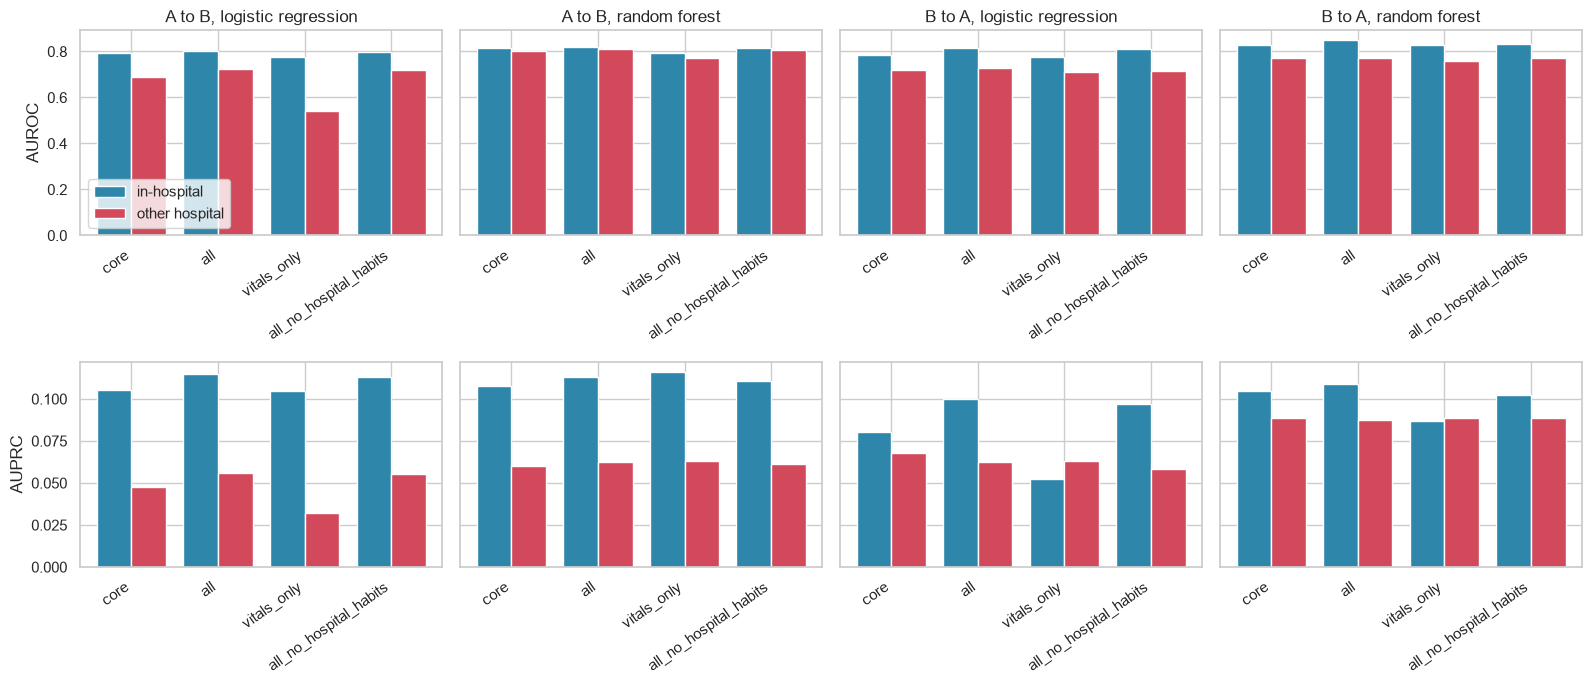

section 7: 477.5 s


In [8]:
XH_SETS = ["core", "all", "vitals_only", "all_no_hospital_habits"]
XH_DIRS = [("A_to_B", "xh_A_to_B"), ("B_to_A", "xh_B_to_A")]
P_XH = TAB / "ablation_cross_hospital.csv"
KEY3 = ["direction", "set", "model"]
XH_COLS = ["direction", "set", "model", "eval_group", "patients", "rows", "base_rate_rows", "auroc", "auprc", "auprc_over_base",
           "sens_at_spec90", "threshold", "sensitivity", "specificity", "precision", "alert_rate"]
XH_USED = {}

def xh_rows(d, s, m, groups, thr):
    out = []
    for g, (y, sc, npat) in groups.items():
        cm, rm = ev.curve_metrics(y, sc), ev.row_metrics(y, sc, thr)
        base = float(y.mean())
        out.append({"direction": d, "set": s, "model": m, "eval_group": g, "patients": npat, "rows": len(y), "base_rate_rows": base,
                    "auroc": cm["auroc"], "auprc": cm["auprc"], "auprc_over_base": cm["auprc"] / base if base > 0 else np.nan,
                    "sens_at_spec90": sens90(y, sc), "threshold": thr, "sensitivity": rm["sensitivity"],
                    "specificity": rm["specificity"], "precision": rm["precision"], "alert_rate": rm["alert_rate"]})
    return out

with timed("section 7"):
    need("inputs", "sets")
    COLS3 = list(dict.fromkeys(c for s in XH_SETS for c in SETS[s]))
    COLPOS3 = {c: i for i, c in enumerate(COLS3)}
    SETIDX3 = {s: np.array([COLPOS3[c] for c in SETS[s]]) for s in XH_SETS}
    done = done_keys(P_XH, KEY3)
    for d, col in XH_DIRS:
        grp = META.patient_id.map(SPL_IDX[col]).astype(str).to_numpy()
        tr_all, va, te = (np.flatnonzero(grp == g) for g in ["train", "val", "test"])
        tr = np.sort(np.random.default_rng(SEED).choice(tr_all, size=XH_TRAIN_ROWS, replace=False)) if len(tr_all) > XH_TRAIN_ROWS else tr_all
        XH_USED[d] = {"train": set(PID_ALL[tr]), "val": set(PID_ALL[va]), "test": set(PID_ALL[te]),
                      "train_hosp": set(HOSP_ALL[tr]), "test_hosp": set(HOSP_ALL[te])}
        pending = [(s, m) for s in XH_SETS for m in MODELS if (d, s, m) not in done]
        log(f"E3 {d}: train {len(tr)} rows, in-hospital val {len(va)} rows, other hospital {len(te)} rows, {len(pending)} fits to run")
        if not pending:
            continue
        rows_all = np.sort(np.concatenate([tr, va, te]))
        Xd, yd = load_block(rows_all, COLS3, desc=d), Y_ALL[rows_all]
        tr_l, va_l, te_l = (np.searchsorted(rows_all, r) for r in (tr, va, te))
        npat_va, npat_te = len(XH_USED[d]["val"]), len(XH_USED[d]["test"])
        for s, m in tqdm(pending, desc=f"E3 {d}"):
            (s_va, s_te), sec = fit_scores(Xd, yd, SETIDX3[s], m, tr_l, [va_l, te_l], "balanced")
            thr = float(ev.best_f2_threshold(yd[va_l], s_va))
            groups = {"in_hospital_val": (yd[va_l], s_va, npat_va), "other_hospital": (yd[te_l], s_te, npat_te)}
            rows = xh_rows(d, s, m, groups, thr)
            append_rows(P_XH, XH_COLS, rows)
            log_fit(f"{d} {s:24s} {m:20s} auroc {rows[0]['auroc']:.3f} -> {rows[1]['auroc']:.3f}  auprc {rows[0]['auprc']:.3f} -> {rows[1]['auprc']:.3f}  {sec:.0f}s")
        del Xd, yd
        gc.collect()

    XH = pd.read_csv(P_XH)
    for (d, s, m), g in XH.groupby(KEY3, sort=False):
        g = g.set_index("eval_group")
        log(f"{d} {s} [{MLAB[m]}]: AUROC {g.loc['in_hospital_val', 'auroc']:.3f} to {g.loc['other_hospital', 'auroc']:.3f} "
            f"(drop {g.loc['in_hospital_val', 'auroc'] - g.loc['other_hospital', 'auroc']:+.3f}), "
            f"AUPRC {g.loc['in_hospital_val', 'auprc']:.3f} to {g.loc['other_hospital', 'auprc']:.3f} "
            f"(drop {g.loc['in_hospital_val', 'auprc'] - g.loc['other_hospital', 'auprc']:+.3f})")

    combos = [(d, m) for d, _ in XH_DIRS for m in MODELS]
    fig, axes = plt.subplots(2, len(combos), figsize=(16, 7), sharey="row")
    x = np.arange(len(XH_SETS))
    for j, (d, m) in enumerate(combos):
        sub = XH[(XH.direction == d) & (XH.model == m)]
        for i, met in enumerate(["auroc", "auprc"]):
            ax = axes[i, j]
            piv = sub.pivot(index="set", columns="eval_group", values=met).loc[XH_SETS]
            ax.bar(x - 0.2, piv["in_hospital_val"], 0.4, color=COL_CTRL, label="in-hospital")
            ax.bar(x + 0.2, piv["other_hospital"], 0.4, color=COL_SEPTIC, label="other hospital")
            ax.set_xticks(x)
            ax.set_xticklabels(XH_SETS, rotation=35, ha="right")
            if i == 0:
                ax.set_title(f"{d.replace('_', ' ')}, {MLAB[m]}")
            if j == 0:
                ax.set_ylabel(met.upper())
    axes[0, 0].legend(loc="lower left")
    save_fig("fig12_cross_hospital.png")
    READY.add("e3")

## E4, hospital-wise test metrics of all saved models

The saved test scores of the earlier models are split by hospital. Thresholds are recomputed from the matching validation score files, with the SIRS rule fixed at 2.

[PASS] scores_m0_m3_test aligned with the first file on patient_id, hour and label (232215 rows)
[PASS] scores_m4_m6_test aligned with the first file on patient_id, hour and label (232215 rows)
[PASS] scores_m7_test aligned with the first file on patient_id, hour and label (232215 rows)
[PASS] scores_m0_m3_val aligned with the first file on patient_id, hour and label (234037 rows)
[PASS] scores_m4_m6_val aligned with the first file on patient_id, hour and label (234037 rows)
[PASS] scores_m7_val aligned with the first file on patient_id, hour and label (234037 rows)
[PASS] every scored test patient has a hospital
[PASS] scored test patients are the test-split patients (6051 patients)


hospital B: 100%|██████████| 12/12 [00:00<00:00, 26.94it/s]


hospital         model   rows  positive_rate  auroc  auprc  threshold  sensitivity  specificity  precision
       A       M0_sirs 118869          0.022  0.604  0.030      2.000        0.490        0.666      0.031
       A         M1_lr 118869          0.022  0.763  0.093      0.716        0.428        0.893      0.081
       A         M2_dt 118869          0.022  0.769  0.092      0.802        0.360        0.931      0.103
       A         M3_rf 118869          0.022  0.813  0.111      0.615        0.460        0.916      0.108
       A    M3b_rf_all 118869          0.022  0.819  0.110      0.603        0.446        0.924      0.115
       A   M4_gnb_core 118869          0.022  0.738  0.087     12.423        0.367        0.937      0.114
       A M4b_bnb_masks 118869          0.022  0.577  0.028     -3.931        0.388        0.745      0.033
       A   M4c_gnb_pca 118869          0.022  0.762  0.079     -3.977        0.444        0.897      0.087
       A        M5_knn 118869        

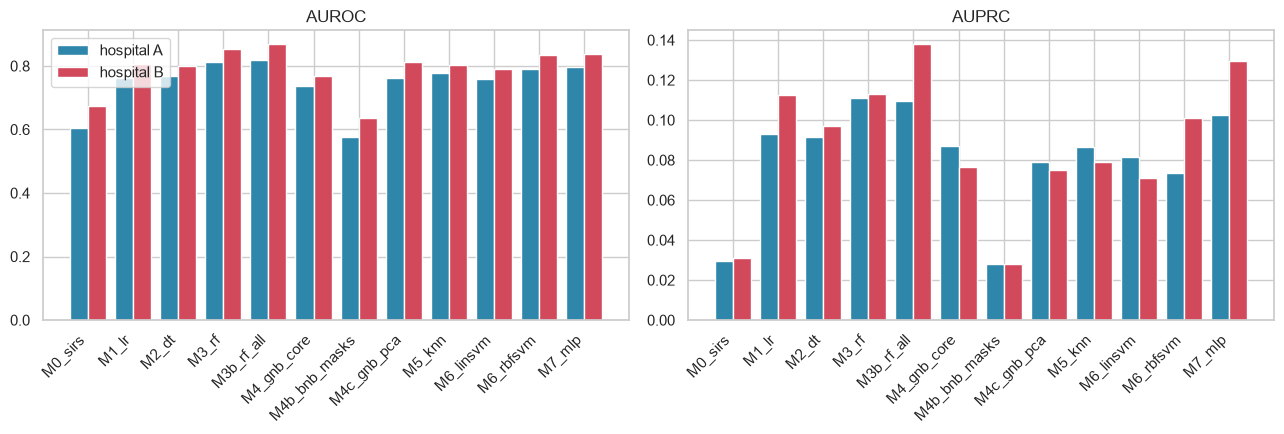

section 8: 2.0 s


In [9]:
M_FILES = [("scores_m0_m3", ["M0_sirs", "M1_lr", "M2_dt", "M3_rf", "M3b_rf_all"]),
           ("scores_m4_m6", ["M4_gnb_core", "M4b_bnb_masks", "M4c_gnb_pca", "M5_knn", "M6_linsvm", "M6_rbfsvm"]),
           ("scores_m7", ["M7_mlp"])]
E4_MODELS = [c for _, cols in M_FILES for c in cols]
KEYS = ["patient_id", "hour", "SepsisLabel"]

def col_values(df, k):
    return df[k].astype(str).to_numpy() if k == "patient_id" else df[k].to_numpy()

def load_scores(part):
    frames = [pd.read_parquet(PROC / f"{stem}_{part}.parquet") for stem, _ in M_FILES]
    base = frames[0][KEYS].copy()
    base["patient_id"] = base["patient_id"].astype(str)
    for (stem, cols), fr in zip(M_FILES, frames):
        same = len(fr) == len(base) and all(np.array_equal(col_values(fr, k), col_values(base, k)) for k in KEYS)
        check(f"{stem}_{part} aligned with the first file on patient_id, hour and label", same, f"{len(fr)} rows")
        for c in cols:
            base[c] = fr[c].to_numpy()
    return base

with timed("section 8"):
    need("inputs")
    TE, VA = load_scores("test"), load_scores("val")
    TE["hospital"] = TE.patient_id.map(SPL_IDX["hospital"])
    check("every scored test patient has a hospital", TE.hospital.notna().all())
    check("scored test patients are the test-split patients", set(TE.patient_id) == set(SPL.loc[SPL.split.astype(str) == "test", "patient_id"]), f"{TE.patient_id.nunique()} patients")
    yv = VA.SepsisLabel.to_numpy()
    THR = {c: 2.0 if c == "M0_sirs" else float(ev.best_f2_threshold(yv, VA[c].to_numpy())) for c in tqdm(E4_MODELS, desc="thresholds")}
    rows = []
    for h in ["A", "B"]:
        d = TE[TE.hospital == h]
        y = d.SepsisLabel.to_numpy()
        for c in tqdm(E4_MODELS, desc=f"hospital {h}"):
            s = d[c].to_numpy()
            cm, rm = ev.curve_metrics(y, s), ev.row_metrics(y, s, THR[c])
            rows.append({"hospital": h, "model": c, "rows": len(d), "positive_rate": float(y.mean()), "auroc": cm["auroc"], "auprc": cm["auprc"],
                         "threshold": THR[c], "sensitivity": rm["sensitivity"], "specificity": rm["specificity"], "precision": rm["precision"]})
    E4 = pd.DataFrame(rows)
    E4.to_csv(TAB / "ablation_hospital_wise_test.csv", index=False)
    print(E4.to_string(index=False))

    fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))
    x, w = np.arange(len(E4_MODELS)), 0.4
    for ax, met in zip(axes, ["auroc", "auprc"]):
        for k, (h, colr) in enumerate([("A", COL_CTRL), ("B", COL_SEPTIC)]):
            d = E4[E4.hospital == h].set_index("model").loc[E4_MODELS]
            ax.bar(x + (k - 0.5) * w, d[met], w, color=colr, label=f"hospital {h}")
        ax.set_xticks(x)
        ax.set_xticklabels(E4_MODELS, rotation=45, ha="right")
        ax.set_title(met.upper())
    axes[0].legend()
    save_fig("fig12_hospital_wise_test.png")
    READY.add("e4")

## Checks and output files

Final checks on the folds, the training rows and the cross-hospital groups. Every saved file is listed with its size and the log is written to disk.

In [10]:
with timed("section 9"):
    with guarded("pool and fold structure"):
        pool_structure_checks("final")

    with guarded("fold disjointness"):
        for f in FOLDS:
            te = heldout_rows(f)
            for name, tr in [("E1", train_rows(f, ABL_TRAIN_ROWS)), ("E2 none", e2_rows("none", f)), ("E2 downsample", e2_rows("downsample", f))]:
                check(f"fold {f}, {name}: training and held-out patients are disjoint", np.intersect1d(PCODE[tr], PCODE[te]).size == 0, f"{len(tr)} train rows, {len(te)} held-out rows")

    with guarded("identical training rows in E1"):
        for f in FOLDS:
            hs = {h for (s, m, ff), h in HASH1.items() if ff == f}
            check(f"E1 fold {f}: one training-row hash across {len(E1_SETS) * len(MODELS)} fits", len(hs) == 1 and len(HASH1) == len(E1_SETS) * len(MODELS) * len(FOLDS), f"{len(hs)} distinct")

    with guarded("identical training rows in E2"):
        for f in FOLDS:
            same_w = {HASH2[(st, m, f)] for st in ["none", "class_weight"] for m in MODELS}
            same_d = {HASH2[("downsample", m, f)] for m in MODELS}
            check(f"E2 fold {f}: none and class_weight share rows, downsample shares rows across models", len(same_w) == 1 and len(same_d) == 1)

    with guarded("row counts of the result files"):
        expect("E1 rows in the folds file", len(pd.read_csv(P_E1)), len(E1_SETS) * len(MODELS) * len(FOLDS))
        expect("E2 rows in the folds file", len(pd.read_csv(P_E2)), len(E2_SETTINGS) * len(MODELS) * len(FOLDS))
        expect("E3 rows in the cross-hospital file", len(pd.read_csv(P_XH)), len(XH_DIRS) * len(XH_SETS) * len(MODELS) * 2)
        expect("E4 rows in the hospital-wise file", len(E4), 2 * len(E4_MODELS))

    with guarded("no AUROC above 0.95"):
        for name, df in [("E1", E1), ("E2", E2), ("E3", XH), ("E4", E4)]:
            check(f"{name}: no AUROC above 0.95", df.auroc.max() <= 0.95, f"max {df.auroc.max():.3f}")

    with guarded("cross-hospital groups"):
        for d, _ in XH_DIRS:
            g, (own, other) = XH_USED[d], d.split("_to_")
            disjoint = not (g["train"] & g["val"]) and not (g["train"] & g["test"]) and not (g["val"] & g["test"])
            check(f"{d}: train, val and test patients are disjoint", disjoint)
            ok = g["test_hosp"] == {other} and g["train_hosp"] == {own} and len(g["test"]) == int((SPL.hospital == other).sum())
            check(f"{d}: test group is exactly hospital {other}", ok, f"{len(g['test'])} patients")

    names = ["ablation_feature_set_definitions.csv", "ablation_feature_sets_folds.csv", "ablation_feature_sets_summary.csv",
             "ablation_paired_differences.csv", "ablation_imbalance_folds.csv", "ablation_imbalance_summary.csv",
             "ablation_cross_hospital.csv", "ablation_hospital_wise_test.csv"]
    figs = ["fig12_feature_set_ablation.png", "fig12_paired_differences.png", "fig12_imbalance.png", "fig12_cross_hospital.png", "fig12_hospital_wise_test.png"]
    for p in [PROC / "feature_sets_v3.json"] + [TAB / n for n in names] + [FIG / n for n in figs]:
        size = f"{p.stat().st_size / 1e6:.2f} MB" if p.exists() else "MISSING"
        check(f"saved {p.relative_to(ROOT)}", p.exists(), size)

    log(f"convergence warnings counted: {N_CONV}")
    log(f"checks: {N_PASS} passed, {N_FAIL} failed")
    out = ROOT / "results" / "step12_summary.txt"
    out.write_text("\n".join(SUMMARY) + "\n")
    print(out)

[PASS] final: pool patients (observed 34285, expected 34285)
[PASS] final: pool rows (observed 1319995, expected 1319995)
[PASS] final: cv_fold is 0 to 4 exactly on the pool patients
[PASS] final: held-out parts of the five folds partition the pool patients (6857, 6857, 6857, 6857, 6857)
[PASS] fold 0, E1: training and held-out patients are disjoint (250000 train rows, 262264 held-out rows)
[PASS] fold 0, E2 none: training and held-out patients are disjoint (500000 train rows, 262264 held-out rows)
[PASS] fold 0, E2 downsample: training and held-out patients are disjoint (94845 train rows, 262264 held-out rows)
[PASS] fold 1, E1: training and held-out patients are disjoint (250000 train rows, 265600 held-out rows)
[PASS] fold 1, E2 none: training and held-out patients are disjoint (500000 train rows, 265600 held-out rows)
[PASS] fold 1, E2 downsample: training and held-out patients are disjoint (94795 train rows, 265600 held-out rows)
[PASS] fold 2, E1: training and held-out patients a